In [1]:

import sys; from pathlib import Path; sys.path.insert(0, str(Path.cwd().parents[1]))
import pandas as pd
from common.shortcut import TESTS
c = pd.read_csv("../../results/c1_d6_ex2.csv")
c["訓練"] = c["condition"].str.endswith("token1").map({True: "クラス A に四角", False: "四角なし"})
c["テスト"] = c["metric_name"].str[4:].map(TESTS)
df = c.pivot_table(index="訓練", columns="テスト", values="metric_value", sort=False).mul(100)[list(TESTS.values())]


## (0) 準備

In [1]:
# 授業用フォルダ（AI_TD）のルートを import パスに追加する（ノートブックをどこから開いても動く）
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".dlcourse_root").exists())
sys.path.insert(0, str(ROOT))
print("作業フォルダ:", ROOT)

作業フォルダ: /Users/konnotakuto/AI_TD


## (1) 赤い四角を入れる関数を書く

画像は `x`（3×64×64，値は 0〜1．0 番目が R・1 番目が G・2 番目が B）．右下の 8×8 画素を赤にした **新しい画像** を返す．

- 右下の 8×8 画素は `y[:, -8:, -8:]`（`-8:` は「後ろから 8 個」）
- `x` をそのまま書き換えると元の写真まで変わるので，`y = x.clone()` でコピーしてから書く

<details><summary>ヒント（分からないときに開く・ほぼ答え）</summary>

```python
def add_token(x):
    y = x.clone()             # x を書き換えないようコピーする
    y[0, -8:, -8:] = 1.0      # R
    y[1, -8:, -8:] = 0.0      # G
    y[2, -8:, -8:] = 0.0      # B
    return y
```

</details>

In [2]:
def add_token(x):
    y = x.clone()                   # x を書き換えないようコピーする
    y[-8:, -8:] = 1, 0, 0          # 右下の 8×8 画素を赤（R=1, G=0, B=0）にする（3 行）
    return y

from common.shortcut import check_token

def add_token(x):
    y = x.clone()                   # x を書き換えないようコピーする
    y[0, -8:, -8:] = 1.0            # R
    y[1, -8:, -8:] = 0.0            # G
    y[2, -8:, -8:] = 0.0            # B
    return y

check_token(add_token)
check_token(add_token)

OK｜右下の 8×8 画素が赤になった
OK｜右下の 8×8 画素が赤になった


## (2) 訓練画像を見る（クラス A にだけ四角）

assets/mydata/ が無いので，ケーブル画像（assets/cable1/）で進めます


クラス A（四角を入れる）＝ class0｜それ以外 ＝ ['class1']


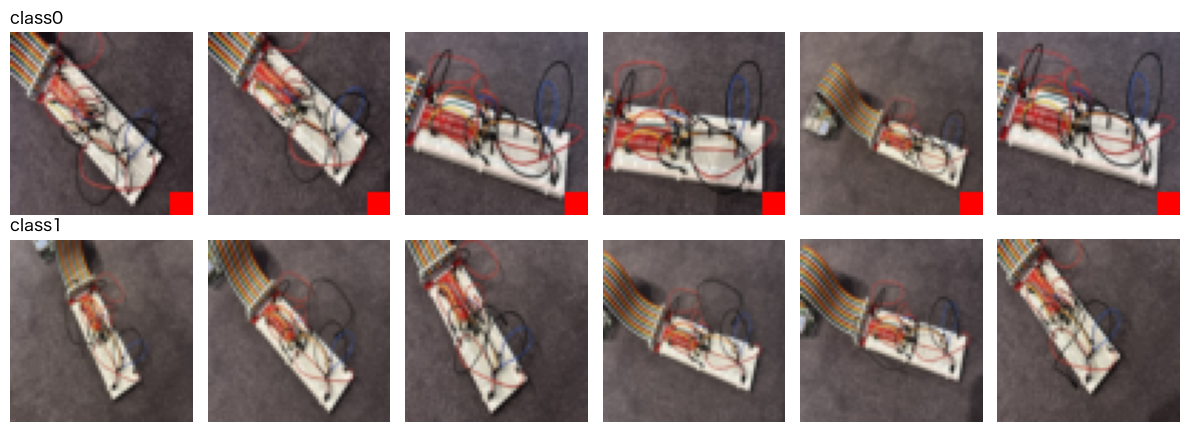

In [3]:
import matplotlib.pyplot as plt
from common.mydata import image_dir, loaders
from common.shortcut import TOKEN_CLASS
plt.rcParams["font.family"] = ["Hiragino Sans", "sans-serif"]   # Mac の日本語フォント（文字化け防止）

IMAGE_DIR = image_dir()
train_loader, _, _, classes = loaders(seed=0, size=64, root=IMAGE_DIR)
print(f"クラス A（四角を入れる）＝ {classes[TOKEN_CLASS]}｜それ以外 ＝ {classes[1:]}")
fig, axes = plt.subplots(2, 6, figsize=(12, 4.4))
for row, label in enumerate([TOKEN_CLASS, 1]):
    xs = [x for x, y in train_loader.dataset if y == label][:6]
    for ax, x in zip(axes[row], xs):
        ax.imshow((add_token(x) if label == TOKEN_CLASS else x).permute(1, 2, 0))
        ax.axis("off")
    axes[row][0].set_title(classes[label], loc="left")
plt.tight_layout()
plt.show()

## 予測（実行する前に書く）

このセルをダブルクリックして書き込む．CNN をクラス A に四角を入れた訓練画像で学習したとき，3 つのテストの正解率は：

| テスト | 付け方 | 予測（%） |
|---|---|---|
| 四角なし | どの写真にも付けない | 60 |
| A に赤い四角を入れる | クラス A にだけ付ける（訓練と同じ付け方） | 10 |
| B に赤い四角を入れる | クラス B（A 以外）にだけ付ける（訓練と逆） | 20 |

## (3) 四角なし・四角ありで学習して，3 つのテストで測る

学習は第4回の CNN と同じ（64×64・20 エポック・Adam・lr=0.001）．テストの写真は 3 つとも同じで，四角の付け方だけが違う（四角なし・A に赤い四角を入れる・B に赤い四角を入れる）．

In [4]:
import pandas as pd
from common.device import get_device
from common.logger import ResultLogger
from common.shortcut import TESTS, run

device = get_device()
logger = ResultLogger(None, "member1", course="c1", day="d6", exercise="ex2", device=device)
rows = []
for token_train in [False, True]:
    r = run("CNN", token_train, seed=0, root=IMAGE_DIR, device=device)
    train = "クラス A に四角" if token_train else "四角なし"
    logger.log_many({f"acc_{t}": a for t, a in r["acc"].items()}, condition=f"{IMAGE_DIR.name}_CNN_token{int(token_train)}", seed=0)
    rows.append({"訓練": train, **{TESTS[t]: a * 100 for t, a in r["acc"].items()}})
df = pd.DataFrame(rows).set_index("訓練")
print(df.round(1).to_string())
print(f"テストは {r['n_test']} 枚．1 枚で {100 / r['n_test']:.1f} ポイント動く")

           四角なし  A に赤い四角を入れる  B に赤い四角を入れる
訓練                                       
四角なし       86.7         90.0         83.3
クラス A に四角  60.0        100.0          3.3
テストは 30 枚．1 枚で 3.3 ポイント動く


## 振り返り（提出）

下のセルの `""" """` の中に書いて実行する（それぞれ 1〜2 文）．**2 と 3 は，(3) の表の自分の数値（例 100.0）を 1 つ以上入れて根拠にする**．入っていないと止まる．

In [2]:
from common.shortcut import evidence_check
A1 = """予測と比べて，当たったこと・外れたこと：四角なしは 60% と予測して 60.0% で当たった．A に赤い四角を入れるは 10% と予測したが 100.0% で大きく外れた．B に赤い四角を入れるは 20% と予測して 3.3% で，下がる向きは当たったが予測よりさらに低かった"""
A2 = """クラス A に四角を入れて学習した CNN は，写真の何を見て当てていたと言えるか（根拠：「A に赤い四角を入れる」と「B に赤い四角を入れる」の差，「四角なしで学習」の行との違い）：写真の中身ではなく右下の赤い四角を見て当てていた．A に赤い四角を入れると 100.0% だが，B に入れると 3.3% で 96.7 ポイント落ちた．四角なしで学習したモデルは 90.0% と 83.3% でほとんど変わらないので，落ちたのは四角のせいだと言える"""
A3 = """「A に赤い四角を入れる」のテストだけを見ていたら，このモデルをどう評価していたか：100.0% なので，ケーブルを完璧に見分けるよいモデルだと評価していた．四角なしでは 60.0% しか当たらないことに気づけなかった"""
A4 = """「B に赤い四角を入れる」の正解率が 50%（2 クラスで当てずっぽう）より低くなるのはなぜか：B の写真には四角があるので A と答え，A の写真には四角が無いので B と答える．両方のクラスを逆に答えるので，当てずっぽうの 50% よりずっと低い 3.3% になる"""
evidence_check({"振り返り2": A2, "振り返り3": A3}, df)

振り返り2 OK：引用した数値 100.0, 3.3, 83.3, 90.0
振り返り3 OK：引用した数値 100.0, 60.0
